In [1]:
!pip install tensorflow==2.21.0

In [2]:
!pip install --upgrade scikeras scikit-learn==1.5.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 98.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn: filename=scikit_learn-1.5.1-cp313-cp313-linux_x86_64.whl size=12152362 sha256=cae3f59c6adf73ee2d0db7fd6bdf7d6c48813a63041b63d675f6457f71604b75
  Stored in directory: /root/.cache/pip/wheels/e2/3f/e6/b9237e0dd0688475370a1b8e4f6247daa3baad6abdaed9fdb9
Successfully built scikit-learn
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikeras]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.12 re

In [3]:
!pip install keras==3.13.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 35.1 MB/s  0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.13.2
    Uninstalling keras-3.13.2:
      Successfully uninstalled keras-3.13.2


In [4]:
!pip install scikeras

In [5]:
import warnings
warnings.filterwarnings('ignore')

# core data hadling & numerical operations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Deep learning framework
import tensorflow as tf
# tensorflow can use tf.keras.Sequential directly
from tensorflow import keras
# Activation can be passed as string inside dense
from tensorflow.keras.regularizers import l2

# from scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RepeatedKFold, KFold #add in (RepeatedKFold, KFold)
from sklearn.metrics import cohen_kappa_score

# bridge between keras & scikit-learn
from scikeras.wrappers import KerasRegressor

tf.keras.utils.set_random_seed(42) #(reproducibility)

from google.colab import files
from pprint import pprint

In [6]:
uploaded = files.upload()

# Load the red wine dataset
df_red = pd.read_csv('winequality-red.csv', sep=';')
#df_red = dataframe.copy() - removed
print("Red wine loaded! Shape:", df_red.shape)
print("Duplicates:", df_red.duplicated().sum()) #check duplicates
print("Missing values:", df_red.isnull().sum().sum()) #check missing values

Saving winequality-red.csv to winequality-red.csv
Red wine loaded! Shape: (1599, 12)
Duplicates: 240
Missing values: 0


In [7]:
print("Number of records per class 'quality'")
print("red wine:")
print(df_red.groupby('quality').size())

Number of records per class 'quality'
red wine:
quality
3     10
4     53
5    681
6    638
7    199
8     18
dtype: int64


**QUALITY HISTOGRAM**

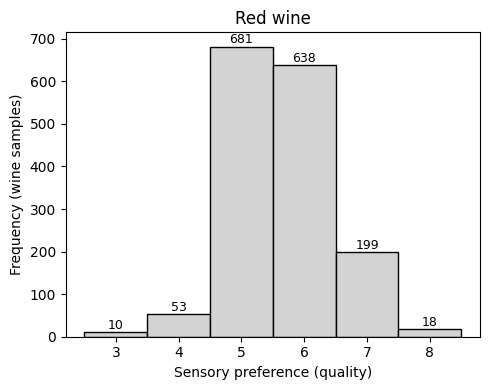

In [8]:
# Paper Fig. 1 equivalent: histogram of the sensory preference (red wine)
fig, ax = plt.subplots(figsize=(5, 4))
counts = df_red['quality'].value_counts().sort_index()
ax.bar(counts.index, counts.values, width=1.0, color='lightgrey', edgecolor='black')
for q, c in counts.items():
    ax.text(q, c + 8, str(c), ha='center', fontsize=9)
ax.set_xlabel('Sensory preference (quality)')
ax.set_ylabel('Frequency (wine samples)')
ax.set_title('Red wine')
plt.tight_layout(); plt.show()

Grade 5 and grade 6 hold the most wine (681 and 638)

The data is imbalanced and in a bell-shaped, rare grades are hard to predict and why the baseline is strong

**CORRELATION HEATMAP** (Spearman correlation)

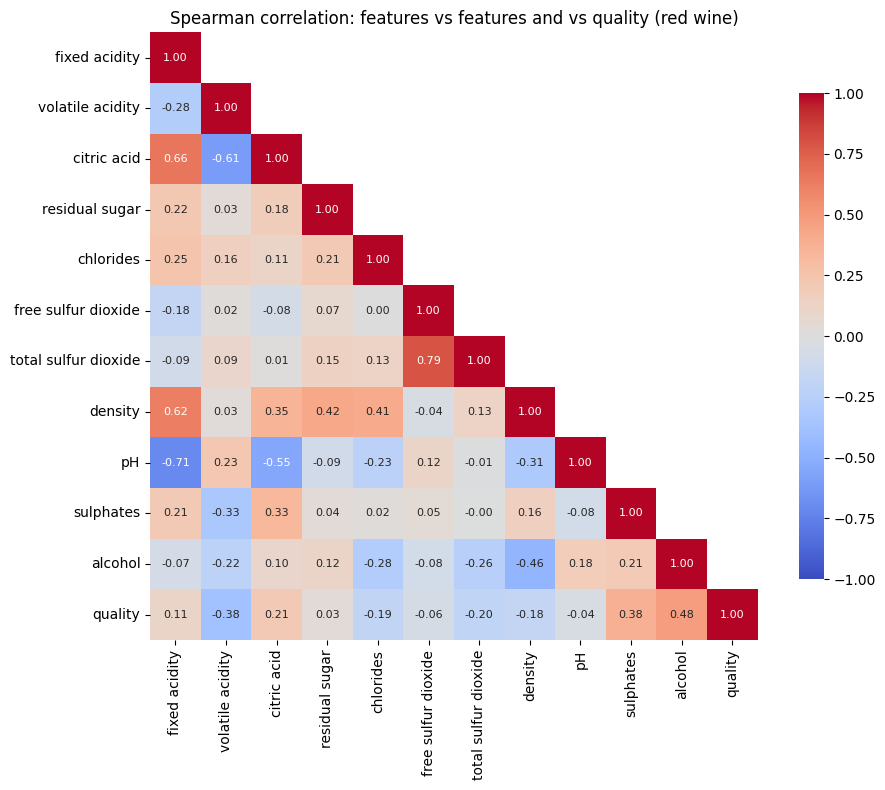

In [9]:
# Correlation heat-map (Spearman: quality is an ordered grade and several features are skewed)
feature_cols = [c for c in df_red.columns if c != 'quality']
corr = df_red.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # show lower triangle only

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, annot_kws={'size': 8}, cbar_kws={'shrink': .8})
plt.title('Spearman correlation: features vs features and vs quality (red wine)')
plt.tight_layout(); plt.show()

Bottom row: Features against quality. **Alcohol** (+0.48), **sulphates** (+0.38) and **volatile acidity** (−0.38) are strongest.

Higher alcohol and sulphates go with **better wine**, and more volatile acidity, which is vinegar-like, goes with **worse wine**.

**Feature-vs-quality bar chart and strongly related pairs**



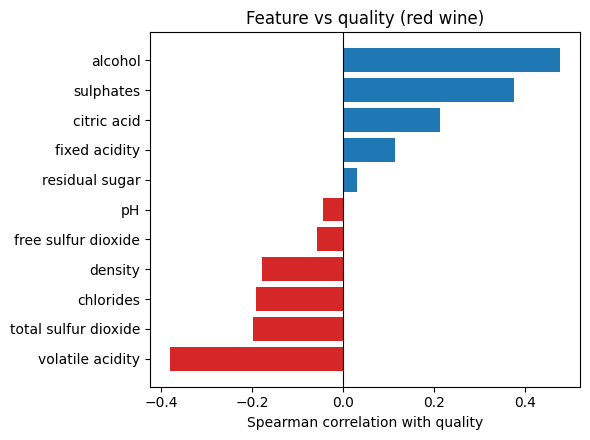

Most strongly related feature pairs:
          feature_1            feature_2   rho
free sulfur dioxide total sulfur dioxide  0.79
      fixed acidity                   pH -0.71
      fixed acidity          citric acid  0.66
      fixed acidity              density  0.62
   volatile acidity          citric acid -0.61
        citric acid                   pH -0.55


In [10]:
# 1) which features move with quality?
cq = corr['quality'].drop('quality').sort_values()
plt.figure(figsize=(6, 4.5))
plt.barh(cq.index, cq.values, color=['tab:red' if v < 0 else 'tab:blue' for v in cq.values])
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Spearman correlation with quality'); plt.title('Feature vs quality (red wine)')
plt.tight_layout(); plt.show()

# 2) which features overlap with each other? (multicollinearity)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().reset_index()
pairs.columns = ['feature_1', 'feature_2', 'rho']
pairs = pairs[(pairs.feature_1 != 'quality') & (pairs.feature_2 != 'quality')]
print('Most strongly related feature pairs:')
print(pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(6).round(2).to_string(index=False))

**BoxPlot and Pair plot**

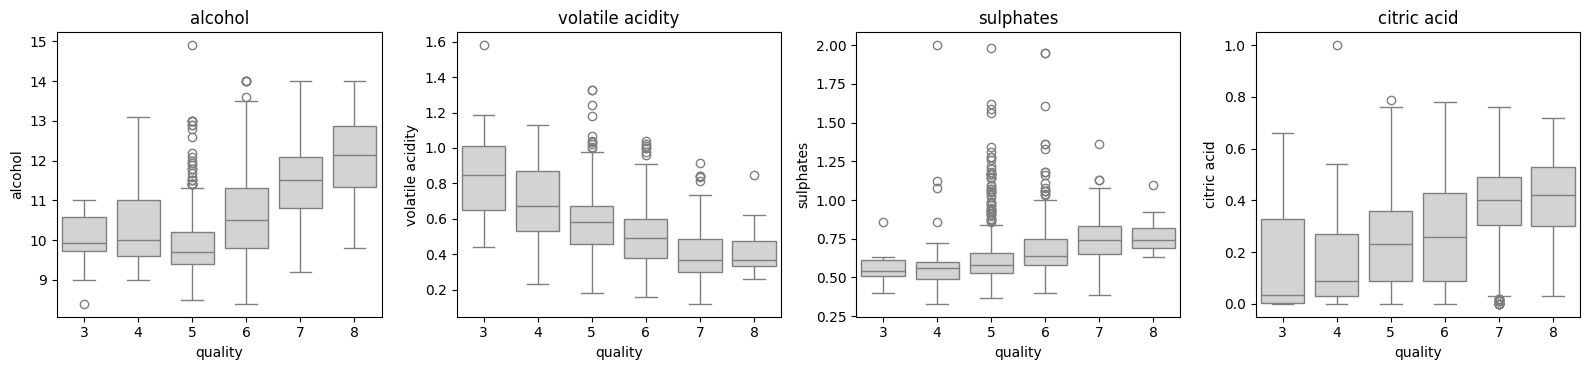

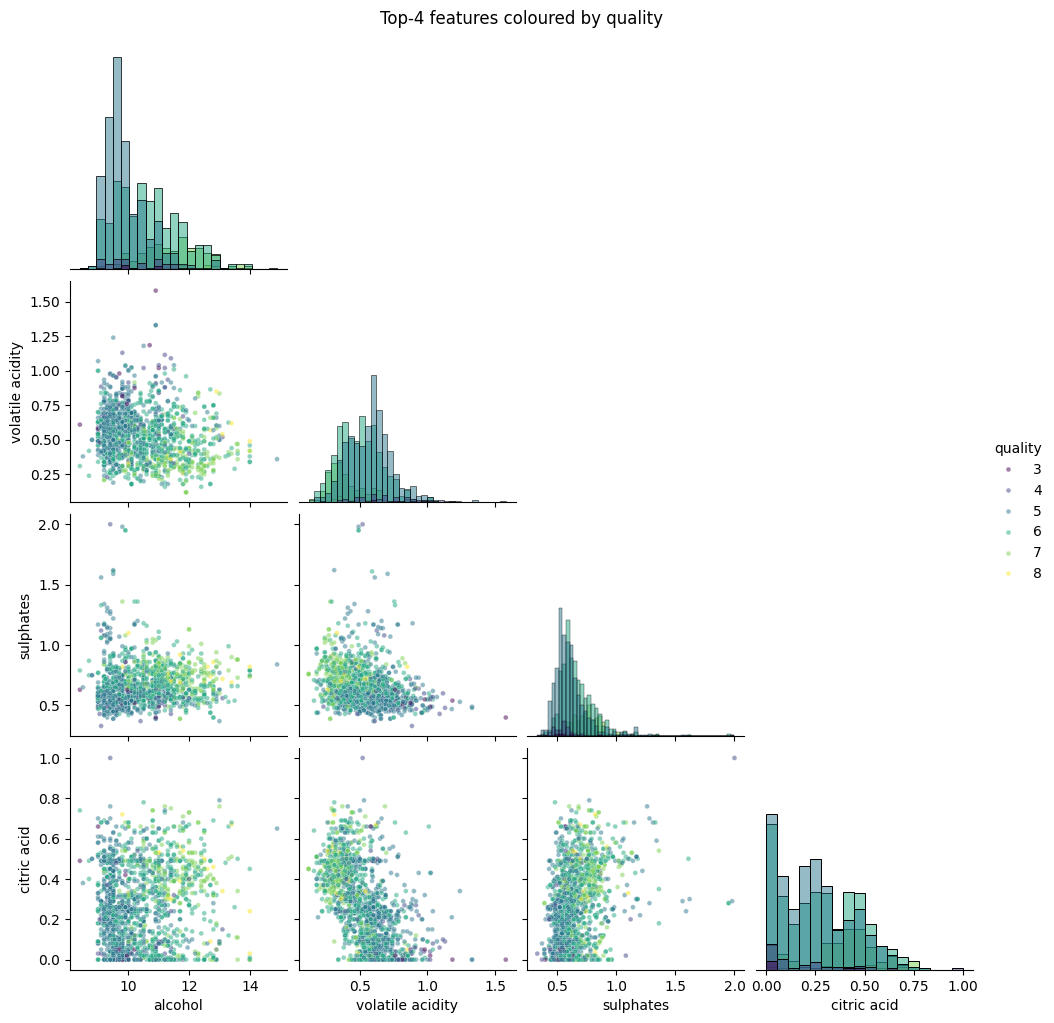

In [11]:
# 3) how do the 4 most quality-related features change across the quality grades?
top4 = list(cq.abs().sort_values(ascending=False).index[:4])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, f in zip(axes, top4):
    sns.boxplot(data=df_red, x='quality', y=f, ax=ax, color='lightgrey')
    ax.set_title(f)
plt.tight_layout(); plt.show()

# 4) pairwise scatter of those features, coloured by quality
g = sns.pairplot(df_red[top4 + ['quality']], hue='quality', palette='viridis',
                 corner=True, diag_kind='hist', plot_kws={'s': 12, 'alpha': 0.5})
g.figure.suptitle('Top-4 features coloured by quality', y=1.02)
plt.show()

Box Plot: Alcohol should rise with quality, and volatile acidity should fall

Pair plot: Expect heavily overlapping colours

No single feature separates the grades cleanly, so this is a hard problem. That is why even the best model gets only about 62% right at T=0.5

In [12]:
target_column = 'quality'
X = df_red.drop(columns=[target_column]).values #numpy array
y = (df_red[target_column]).astype(float) #keep the 3-8 grades

In [13]:
N_FEATURES = X.shape[1]

def build_ann(n_hidden=1, n_neurons=16, reg_param=0.001, learning_rate= 0.001):
  model = keras.models.Sequential()
  model.add(keras.Input(shape=(N_FEATURES,)))

  # dynamically add hidden layers based on hyperparameter tuning
  # this for loop add  n_hidden layers to the model, each with n_neurons
  # and a ReLU activation function
  for _ in range(n_hidden):
    model.add(keras.layers.Dense(
        n_neurons,
        activation='relu',
        kernel_regularizer=l2(reg_param)
    ))


  model.add(keras.layers.Dense(1))

  # compile with optimizer, learning rate, loss, metrics
  model.compile(
      loss='mse',
      optimizer=keras.optimizers.Adam(learning_rate=learning_rate)

  )

  return model

In [14]:
from scipy.stats import norm, t as t_dist
from sklearn.metrics import f1_score, balanced_accuracy_score, log_loss

CLASSES = np.arange(3, 9)                       # grades that exist in the red-wine data: 3..8

def to_class(pred):
    """Round regression output to the nearest valid grade (paper: T = 0.5)."""
    return np.clip(np.rint(pred), CLASSES.min(), CLASSES.max()).astype(int)

def class_proba(pred, sigma):
    """Regression output -> probabilities over grades 3..8 (discretised Gaussian, rows sum to 1)."""
    pred = np.asarray(pred, dtype=float)
    inner = CLASSES[:-1] + 0.5                                  # 3.5, 4.5, ..., 7.5
    cdf = norm.cdf((inner[None, :] - pred[:, None]) / sigma)
    cdf = np.hstack([np.zeros((len(pred), 1)), cdf, np.ones((len(pred), 1))])
    return np.diff(cdf, axis=1)

def paper_metrics(y_true, y_pred, proba=None):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    err = np.abs(y_true - y_pred)
    yt, yp = y_true.astype(int), to_class(y_pred)
    out = {
        'MAD':        err.mean(),
        'Acc_T0.25':  np.mean(err <= 0.25) * 100,
        'Acc_T0.50':  np.mean(err <= 0.50) * 100,
        'Acc_T1.00':  np.mean(err <= 1.00) * 100,
        'Kappa_T0.5': cohen_kappa_score(yt, yp, labels=CLASSES) * 100,
        'QWK':        cohen_kappa_score(yt, yp, weights='quadratic', labels=CLASSES) * 100,
        'Macro_F1':   f1_score(yt, yp, labels=CLASSES, average='macro', zero_division=0) * 100,
        'Bal_Acc':    balanced_accuracy_score(yt, yp) * 100,
    }
    if proba is not None:
        out['LogLoss'] = log_loss(yt, proba, labels=CLASSES)
    return out

In [15]:

# wrap the model using KerasClassifier
# [CHANGED] KerasRegressor inside a Pipeline, so the scaler is fit on the training part of each CV split
ann_reg = KerasRegressor(
    model=build_ann,
    n_hidden=1, # Default value, will be overridden by GridSearchCV
    n_neurons=16, # Default value, will be overridden by GridSearchCV
    reg_param=0.001, # Default value, will be overridden by GridSearchCV
    learning_rate=0.001, # Default value, will be overridden by GridSearchCV
    epochs=100, # Default value, will be overridden by GridSearchCV          # [CHANGED] more epochs, early stopping handles the rest
    batch_size=32, # Default value, will be overridden by GridSearchCV
    validation_split=0.15, # Default value, will be overridden by GridSearchCV  # [NEW] needed for early stopping
    callbacks=[keras.callbacks.EarlyStopping(patience=10,restore_best_weights=True)],
    verbose=0
)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ann', ann_reg)
]) # new

# Fine-Tuning Neural Network Hyperparameters for the model
# Define the Grid with 3 parameters you want to fine tune, 3 candidate values each
param_grid = {
    'ann__model__n_hidden': [1, 2, 3],
    'ann__model__n_neurons': [16, 32, 64],
    'ann__model__reg_param': [0.0001, 0.001, 0.01],
}

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=KFold(3, shuffle=True, random_state=42), # 3-fold cross-validation # shuffled folds
    scoring='neg_mean_absolute_error',             # matches the paper's MAD
    n_jobs=1,
    error_score='raise',
    #return_train_score=True,
    verbose=1
)

print("Running Grid Search (this may take a moment)...")
grid_search.fit(X, y)
print("Grid search finished!")

Running Grid Search (this may take a moment)...
Fitting 3 folds for each of 27 candidates, totalling 81 fits
Grid search finished!


In [16]:
best_params = grid_search.best_params_
pprint(best_params)
print(f"Best CV MAD: {-grid_search.best_score_:.3f}")           # MAD is the negated score

{'ann__model__n_hidden': 2,
 'ann__model__n_neurons': 32,
 'ann__model__reg_param': 0.01}
Best CV MAD: 0.500


In [17]:
# ---- the ANN chosen by the grid search (unchanged from before) -------------------------------
def make_best_model():
    p = {k.replace('ann__model__', ''): v for k, v in best_params.items()}
    return build_ann_model_from(p)

def build_ann_model_from(p):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('ann', KerasRegressor(
            model=build_ann, **{f"model__{k}": v for k, v in p.items()},
            epochs=100, batch_size=32, validation_split=0.15,
            callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
            verbose=0))
    ])

# ---- comparison models: same ones as the paper (MR and SVM) -----------------------------------
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict

def fit_mr(Xtr, ytr):
    """Multiple regression (the paper's MR)."""
    return Pipeline([('scaler', StandardScaler()), ('mr', LinearRegression())]).fit(Xtr, ytr)

class PaperSVR:
    """SVM regression set up as in the paper: Gaussian kernel, C=3, epsilon from the kNN heuristic,
    gamma searched over {2^3, 2^1, ..., 2^-15} using an internal 3-fold validation (MAD)."""
    def fit(self, X, y):
        self.sx = StandardScaler().fit(X)
        self.sy = StandardScaler().fit(np.asarray(y).reshape(-1, 1))
        Xs = self.sx.transform(X)
        ys = self.sy.transform(np.asarray(y).reshape(-1, 1)).ravel()
        knn = cross_val_predict(KNeighborsRegressor(3), Xs, ys, cv=5)
        sigma_hat = np.sqrt(1.5 / len(ys) * np.sum((ys - knn) ** 2))
        eps = sigma_hat / np.sqrt(len(ys))
        gs = GridSearchCV(SVR(kernel='rbf', C=3, epsilon=eps),
                          {'gamma': 2.0 ** np.arange(3, -16, -2)},
                          cv=KFold(3, shuffle=True, random_state=42),
                          scoring='neg_mean_absolute_error')
        gs.fit(Xs, ys)
        self.svr, self.gamma_ = gs.best_estimator_, gs.best_params_['gamma']
        return self
    def predict(self, X):
        p = self.svr.predict(self.sx.transform(X)).reshape(-1, 1)
        return self.sy.inverse_transform(p).ravel()

# ---- paper Section 2.4: sensitivity analysis -> relative importance Ra (%) --------------------
def sensitivity_importance(model, X_train, L=5):
    """Vary one input over L levels (-1 ... +1 std) with all others at their mean;
    importance = variance of the model output, as a % of the total (paper Eq. 4)."""
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    levels = np.linspace(-1, 1, L)
    V = []
    for a in range(X_train.shape[1]):
        grid = np.tile(mu, (L, 1))
        grid[:, a] = mu[a] + levels * sd[a]
        yhat = np.asarray(model.predict(grid)).ravel()
        V.append(np.sum((yhat - yhat.mean()) ** 2) / (L - 1))
    V = np.array(V)
    return V / V.sum() * 100

In [18]:
DROP_DUPLICATES = False      # the paper kept the duplicated rows; set True to test how much they inflate the scores
N_REPEATS = 3                # paper: 20. Use 20 for the final run (slow for the ANN)

y_arr = np.asarray(y, dtype=float)
if DROP_DUPLICATES:
    keep = ~df_red.duplicated().values
    X_eval, y_eval = X[keep], y_arr[keep]
else:
    X_eval, y_eval = X, y_arr
print('Evaluating on', len(y_eval), 'wines')

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=42)

MODELS = ['Majority', 'MR', 'SVR', 'ANN']
rows  = {m: [] for m in MODELS}         # per-fold metrics
preds = {m: [] for m in MODELS}         # per-fold test predictions
trues = []                              # per-fold true grades
imp   = {'SVR': [], 'ANN': []}          # per-fold sensitivity importances

for tr, te in rskf.split(X_eval, y_eval.astype(int)):
    ytr, yte = y_eval[tr], y_eval[te]
    trues.append(yte)

    # --- majority-class baseline: always the most common training grade, class frequencies as probabilities
    maj = np.bincount(ytr.astype(int)).argmax()
    prior = np.array([(ytr.astype(int) == c).mean() for c in CLASSES])
    p_te = np.full(len(te), float(maj))
    rows['Majority'].append(paper_metrics(yte, p_te, np.tile(prior, (len(te), 1))))
    preds['Majority'].append(p_te)

    # --- the three real models, all trained on the same training fold
    fitted = {'MR':  fit_mr(X_eval[tr], ytr),
              'SVR': PaperSVR().fit(X_eval[tr], ytr),
              'ANN': make_best_model().fit(X_eval[tr], ytr)}
    for name, mdl in fitted.items():
        p_tr = np.asarray(mdl.predict(X_eval[tr])).ravel()
        p_te = np.asarray(mdl.predict(X_eval[te])).ravel()
        sigma = (ytr - p_tr).std()                       # for the log-loss probabilities
        rows[name].append(paper_metrics(yte, p_te, class_proba(p_te, sigma)))
        preds[name].append(p_te)
        if name in imp:
            imp[name].append(sensitivity_importance(mdl, X_eval[tr]))

res_by_model = {m: pd.DataFrame(rows[m]) for m in MODELS}
print('done:', len(trues), 'folds per model')

Evaluating on 1599 wines
done: 15 folds per model


**RESULT TABLE**

In [19]:
order = ['MAD', 'Acc_T0.25', 'Acc_T0.50', 'Acc_T1.00', 'Kappa_T0.5', 'QWK', 'Macro_F1', 'Bal_Acc', 'LogLoss']

mean_tbl = pd.DataFrame({m: res_by_model[m].mean() for m in MODELS}).T[order]
std_tbl  = pd.DataFrame({m: res_by_model[m].std()  for m in MODELS}).T[order]

print('Table A - same folds, mean +/- std over', len(trues), 'folds')
print('(MAD and LogLoss: lower is better; everything else: higher is better)')
fmt = pd.DataFrame({c: [f'{mean_tbl.loc[m, c]:.2f} ± {std_tbl.loc[m, c]:.2f}' for m in mean_tbl.index]
                    for c in mean_tbl.columns}, index=mean_tbl.index)
display(fmt)

# Table B: paper vs my models (only the metrics the paper reports)
paper = pd.DataFrame({
    'MAD':        [0.50, 0.51, 0.46],
    'Acc_T0.25':  [31.2, 31.1, 43.2],
    'Acc_T0.50':  [59.1, 59.1, 62.4],
    'Acc_T1.00':  [88.6, 88.8, 89.0],
    'Kappa_T0.5': [32.2, 32.5, 38.7],
}, index=['Paper MR', 'Paper NN', 'Paper SVM'])
mine = mean_tbl.loc[['Majority', 'MR', 'SVR', 'ANN'], paper.columns].round({'MAD': 2, 'Acc_T0.25': 1, 'Acc_T0.50': 1, 'Acc_T1.00': 1, 'Kappa_T0.5': 1})
mine.index = ['My Majority', 'My MR', 'My SVR', 'My ANN']
print('\nTable B - published vs this notebook')
display(pd.concat([paper, mine]))

Table A - same folds, mean +/- std over 15 folds
(MAD and LogLoss: lower is better; everything else: higher is better)


,MAD,Acc_T0.25,Acc_T0.50,Acc_T1.00,Kappa_T0.5,QWK,Macro_F1,Bal_Acc,LogLoss
Majority,0.73 ± 0.00,42.59 ± 0.13,42.59 ± 0.13,85.80 ± 0.15,0.00 ± 0.00,0.00 ± 0.00,9.96 ± 0.02,16.67 ± 0.00,1.18 ± 0.00
MR,0.51 ± 0.02,31.39 ± 2.55,59.23 ± 2.14,88.56 ± 1.14,32.42 ± 3.66,49.30 ± 3.06,26.54 ± 1.71,26.50 ± 1.32,1.00 ± 0.02
SVR,0.46 ± 0.01,43.24 ± 2.58,62.12 ± 2.52,88.62 ± 1.40,38.27 ± 4.30,55.29 ± 2.68,30.02 ± 1.47,30.04 ± 1.56,0.99 ± 0.04
ANN,0.50 ± 0.02,33.56 ± 3.83,60.25 ± 2.61,88.53 ± 1.11,35.08 ± 4.58,52.96 ± 4.27,29.03 ± 1.90,28.63 ± 1.76,0.99 ± 0.04



Table B - published vs this notebook


,MAD,Acc_T0.25,Acc_T0.50,Acc_T1.00,Kappa_T0.5
Paper MR,0.50,31.2,59.1,88.6,32.2
Paper NN,0.51,31.1,59.1,88.8,32.5
Paper SVM,0.46,43.2,62.4,89.0,38.7
My Majority,0.73,42.6,42.6,85.8,0.0
My MR,0.51,31.4,59.2,88.6,32.4
My SVR,0.46,43.2,62.1,88.6,38.3
My ANN,0.50,33.6,60.2,88.5,35.1


TABLE A: ANN beat the Baseline, but but it no better then MR, lose to SVR

MAD and Log loss are lower-is-better

TABLE B: My re-implementation reproduces the paper’s SVM, so my pipeline is validated. [My ANN] is on par with / below the paper’s MR and NN.”

**CORRECTED T-TEST TABLE** (Repeated CV folds overlap, and an ordinary t-test would be over-confident.)

In [20]:
# Is the ANN really better/worse? Corrected resampled t-test (Nadeau & Bengio, 2003).
# Folds of repeated CV overlap, so a plain paired t-test is over-confident; the correction fixes this.
def corrected_ttest(a, b, test_over_train=0.25):       # 5-fold CV: test/train = 1/4
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + test_over_train) * d.var(ddof=1))
    return d.mean(), t, 2 * t_dist.sf(abs(t), df=k - 1)

lower_is_better = {'MAD', 'LogLoss'}
out = []
for other in ['Majority', 'MR', 'SVR']:
    for metric in ['MAD', 'Acc_T0.50', 'QWK', 'Macro_F1', 'Bal_Acc', 'LogLoss']:
        diff, t, p = corrected_ttest(res_by_model['ANN'][metric], res_by_model[other][metric])
        better = (diff < 0) if metric in lower_is_better else (diff > 0)
        verdict = 'n.s.' if p >= 0.05 else ('ANN better' if better else 'ANN worse')
        out.append({'ANN vs': other, 'metric': metric, 'ANN - other': round(diff, 3),
                    'p-value': round(p, 4), 'verdict (95%)': verdict})
display(pd.DataFrame(out))

,ANN vs,metric,ANN - other,p-value,verdict (95%)
0,Majority,MAD,-0.231,0.0000,ANN better
1,Majority,Acc_T0.50,17.658,0.0000,ANN better
2,Majority,QWK,52.965,0.0000,ANN better
3,Majority,Macro_F1,19.072,0.0000,ANN better
4,Majority,Bal_Acc,11.966,0.0000,ANN better
5,Majority,LogLoss,-0.196,0.0000,ANN better
6,MR,MAD,-0.009,0.2198,n.s.
7,MR,Acc_T0.50,1.021,0.4109,n.s.
8,MR,QWK,3.666,0.0370,ANN better
9,MR,Macro_F1,2.488,0.0636,n.s.


ANN versus MR is [n.s.], so adding a neural network did not improve on linear regression for this dataset

**REC CURVE**

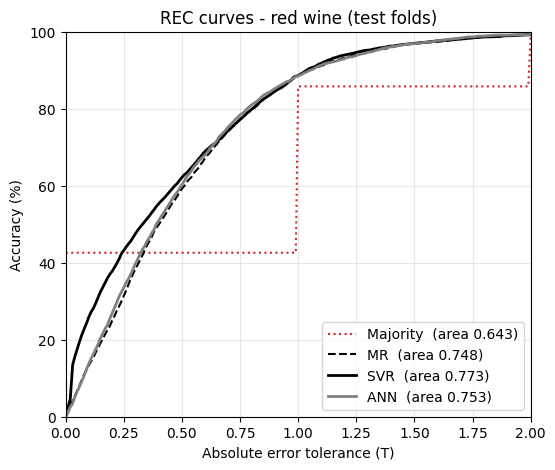

In [21]:
# Paper Fig. 3 equivalent: REC curves (SVM solid black, NN grey, MR dashed; majority baseline added in red)
trapz = getattr(np, 'trapezoid', None) or np.trapz
y_true_all = np.concatenate(trues)
tol = np.linspace(0, 2, 201)
style = {'SVR': dict(color='black', ls='-', lw=2),
         'ANN': dict(color='grey',  ls='-', lw=2),
         'MR':  dict(color='black', ls='--', lw=1.5),
         'Majority': dict(color='tab:red', ls=':', lw=1.5)}

plt.figure(figsize=(6, 5))
rec_area = {}
for m in ['Majority', 'MR', 'SVR', 'ANN']:
    errs = np.abs(y_true_all - np.concatenate(preds[m]))
    acc = np.array([(errs <= t).mean() for t in tol]) * 100
    rec_area[m] = trapz(acc / 100, tol) / tol[-1]          # ideal model = 1.0
    plt.plot(tol, acc, label=f'{m}  (area {rec_area[m]:.3f})', **style[m])
plt.xlabel('Absolute error tolerance (T)'); plt.ylabel('Accuracy (%)')
plt.xlim(0, 2); plt.ylim(0, 100)
plt.title('REC curves - red wine (test folds)'); plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.show()

higher curve is better, and the area under it summarises this (ideal = 1.0).

The SVR wins where precision matters most, at small tolerances. [MY ANN] sits [ MR / between MR and SVR].

**CONFUSION MATRIX**

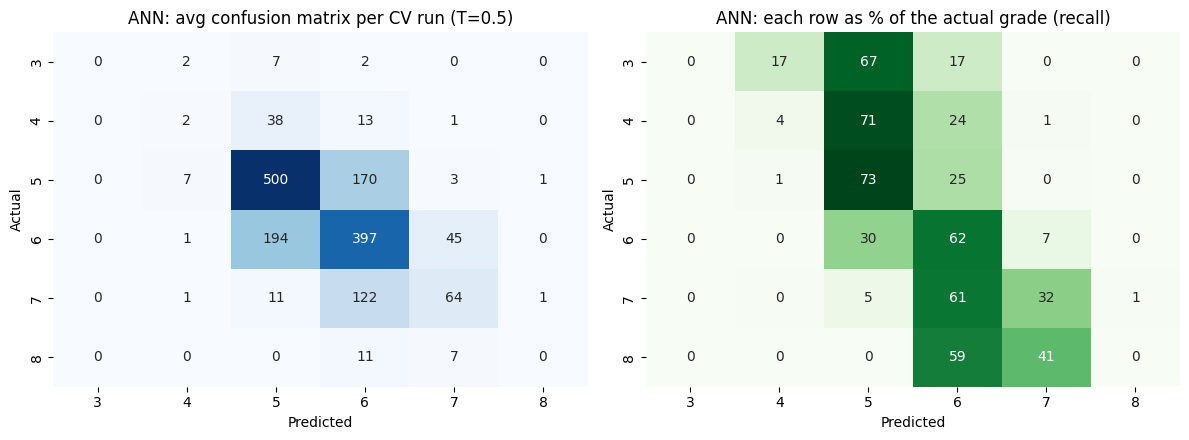

,3,4,5,6,7,8
Precision T=0.5 (%),NaN,16.2,66.7,55.6,53.2,0.0
Precision T=1.0 (%),NaN,82.8,90.9,86.0,90.7,60.0


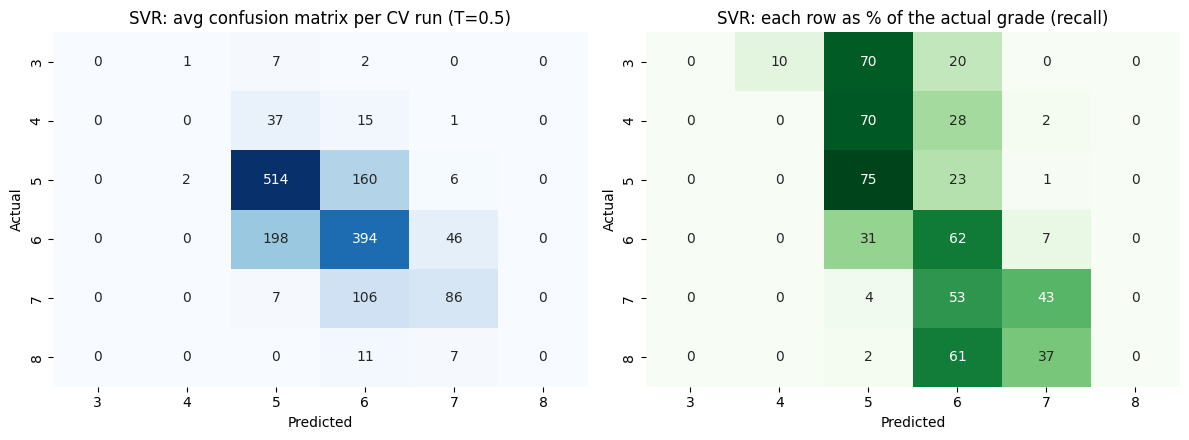

,3,4,5,6,7,8
Precision T=0.5 (%),NaN,0.0,67.3,57.3,58.9,NaN
Precision T=1.0 (%),100.0,94.1,90.3,86.4,90.4,100.0


In [22]:
# Paper Table 3 equivalent: confusion matrix (T=0.5) and precision (T=0.5 and T=1.0)
def tolerance_pred(y_true, y_pred, T):
    """Paper's rule: if |y - y_hat| <= T the prediction counts as the true class,
    otherwise it is the closest class to y_hat that is not the true class."""
    y_true = y_true.astype(int); out = np.empty_like(y_true)
    for i, (yt, yp) in enumerate(zip(y_true, y_pred)):
        if abs(yt - yp) <= T:
            out[i] = yt
        else:
            cand = CLASSES[CLASSES != yt]
            out[i] = cand[np.argmin(np.abs(cand - yp))]
    return out

def show_confusion(name):
    y_pred_all = np.concatenate(preds[name])
    y_int = y_true_all.astype(int)
    p05 = tolerance_pred(y_true_all, y_pred_all, 0.5)
    cm = (pd.crosstab(y_int, p05).reindex(index=CLASSES, columns=CLASSES, fill_value=0) / N_REPEATS)
    cm.index.name, cm.columns.name = 'Actual', 'Predicted'

    prec = {}
    for T in (0.5, 1.0):
        p = tolerance_pred(y_true_all, y_pred_all, T)
        prec[f'Precision T={T} (%)'] = [100 * np.sum((p == c) & (y_int == c)) / np.sum(p == c)
                                        if np.sum(p == c) else np.nan for c in CLASSES]
    prec = pd.DataFrame(prec, index=CLASSES).T.round(1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=axes[0])
    axes[0].set_title(f'{name}: avg confusion matrix per CV run (T=0.5)')
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0) * 100, annot=True, fmt='.0f', cmap='Greens', cbar=False, ax=axes[1])
    axes[1].set_title(f'{name}: each row as % of the actual grade (recall)')
    plt.tight_layout(); plt.show()
    display(prec)

show_confusion('ANN')
show_confusion('SVR')       # to compare with the paper's SVM table

Pattern shows: Predictions cluster on grades 5 and 6, and grades 3, 4 and 8 are almost never predicted

The ANN [never/rarely] predicts the extreme grades because they are rare. That is why Macro-F1 is much lower than accuracy

**INPUT IMPORTANCE**

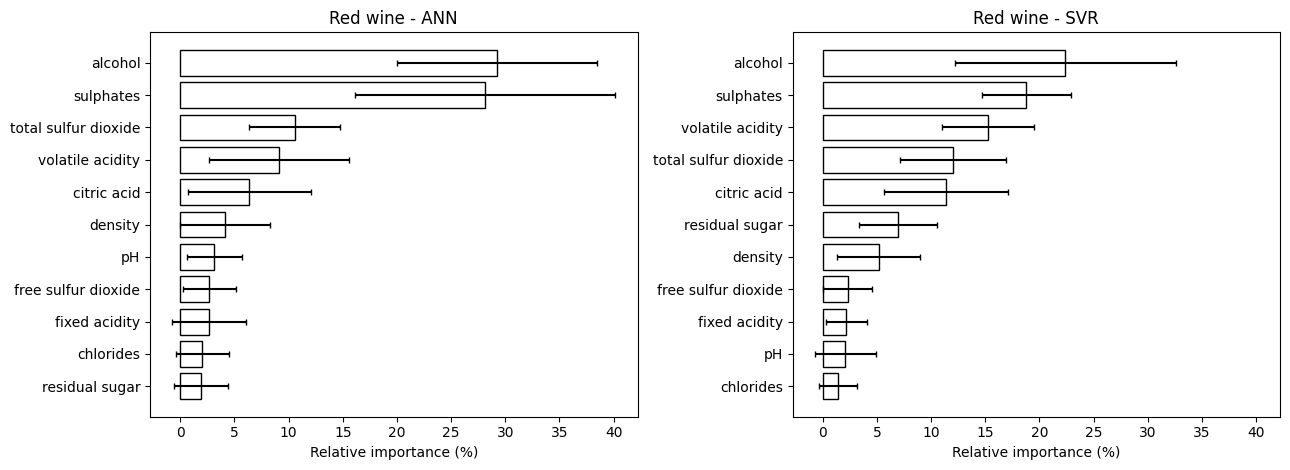

,Spearman corr. with quality,ANN importance (%),SVR importance (%)
alcohol,0.48,29.24,22.39
sulphates,0.38,28.15,18.78
total sulfur dioxide,-0.20,10.56,12.03
volatile acidity,-0.38,9.12,15.29
citric acid,0.21,6.37,11.37
density,-0.18,4.16,5.19
pH,-0.04,3.14,2.09
free sulfur dioxide,-0.06,2.67,2.33
fixed acidity,0.11,2.66,2.17
chlorides,-0.19,2.03,1.41


In [23]:
# Paper Fig. 4 equivalent: relative importance of the inputs (sensitivity analysis, mean over all folds)
feat_names = [c for c in df_red.columns if c != 'quality']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, name in zip(axes, ['ANN', 'SVR']):
    arr = np.array(imp[name])
    m, s = arr.mean(axis=0), arr.std(axis=0)
    order_i = np.argsort(m)                                 # least important at the bottom
    ax.barh(np.array(feat_names)[order_i], m[order_i], xerr=s[order_i],
            color='white', edgecolor='black', capsize=2)
    ax.set_title(f'Red wine - {name}'); ax.set_xlabel('Relative importance (%)')
plt.tight_layout(); plt.show()

# Do the models rely on the features that are correlated with quality?
imp_tbl = pd.DataFrame({
    'Spearman corr. with quality': corr['quality'].drop('quality'),
    'ANN importance (%)': np.array(imp['ANN']).mean(axis=0),
    'SVR importance (%)': np.array(imp['SVR']).mean(axis=0),
}, index=feat_names).round(2).sort_values('ANN importance (%)', ascending=False)
display(imp_tbl)

The paper’s SVM also ranks sulphates and alcohol highest. My ANN ranks alcohol, sulphates and  which agrees to SVM